In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [40]:
df = pd.read_csv('datasets/Mall_Customers.csv')

In [41]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [43]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [45]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = sorted(distances[:, -1])

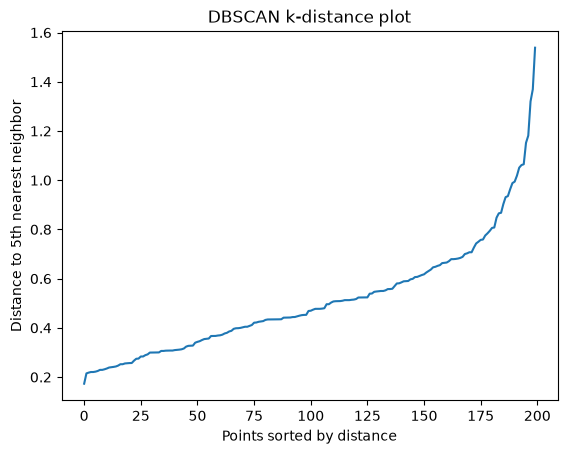

In [46]:
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("DBSCAN k-distance plot")
plt.show()

In [47]:
# Start with these values, then compare a few eps values
dbscan = DBSCAN(eps=0.7, min_samples=min_samples)
df["Cluster"] = dbscan.fit_predict(X_scaled)

In [48]:
# DBSCAN labels noise points as -1
n_clusters = len(set(df["Cluster"])) - (1 if -1 in df["Cluster"].values else 0)
n_noise = (df["Cluster"] == -1).sum()
print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise} of {len(df)}")


Clusters found: 1
Noise points: 14 of 200


In [49]:
# Summarize each cluster (excluding noise)
print(
    df[df["Cluster"] != -1]
    .groupby("Cluster")[features]
    .mean()
    .round(1)
)

          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        39.6                59.5                    51.3


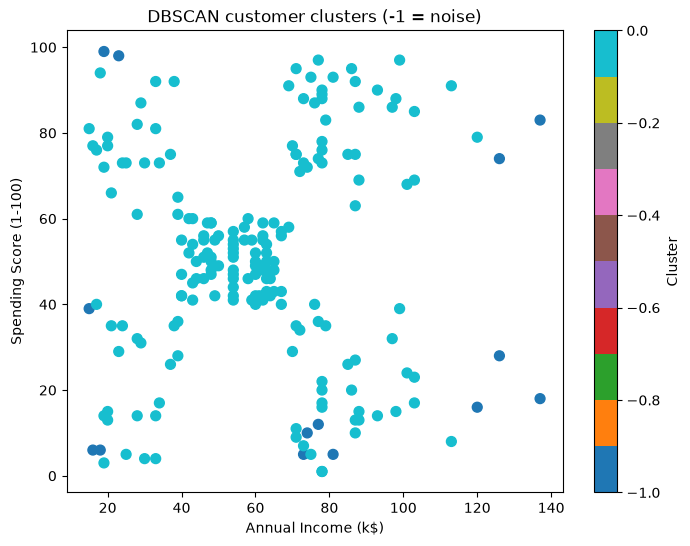

In [50]:
# Plot income vs. spending score, colored by DBSCAN cluster
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="tab10",
    s=50
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN customer clusters (-1 = noise)")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [53]:
# Example new customer: age, annual income (k$), spending score
new_customer = pd.DataFrame([[5, 0, 90]], columns=features)
new_customer_scaled = scaler.transform(new_customer)

# DBSCAN has no predict() method, so refit with the new customer included
combined_scaled = np.vstack([X_scaled, new_customer_scaled])
combined_model = DBSCAN(eps=dbscan.eps, min_samples=dbscan.min_samples)
combined_labels = combined_model.fit_predict(combined_scaled)
new_label = combined_labels[-1]
print(new_label)
# print("New customer:", dict(zip(features, new_customer.iloc[0])))
# if new_label == -1:
#     print("Analysis: this customer is noise (not in a dense cluster).")
# else:
#     print(f"Analysis: this customer belongs to cluster {new_label}.")

-1
